# Data Collection and Preparation:
- ingesting the data in appropriate format (Unsere Jungs fragen: [1,2,3,4] -> [1,2] + [3], [2,3] + [4]) + fragen: was die anderen unter data ingestion verstehen? (Beide Datensätze mergen?)
- checking for missing or erroneous data
- cleaning your dataset

Dicuss our assumption
Was mit Datensätzen machen, die Prozesschritte nicht einhalten?

In [2]:
import pandas as pd
import ast
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Ingesting the data
data_weather = pd.read_csv("../data/weather_burbank_airport.csv")


data_charge = pd.read_csv("../data/charging_sessions.csv")

In [4]:
# Get a brief overview
data_weather.head(3)

,city,timestamp,temperature,cloud_cover,cloud_cover_description,pressure,windspeed,precipitation,felt_temperature
0,Burbank,2018-01-01 08:53:00,9.0,33.0,Fair,991.75,9.0,0.0,8.0
1,Burbank,2018-01-01 09:53:00,9.0,33.0,Fair,992.08,0.0,0.0,9.0
2,Burbank,2018-01-01 10:53:00,9.0,21.0,Haze,992.08,0.0,0.0,9.0


In [5]:
# Get a brief overview
data_charge.head(3)

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
0,0,5e23b149f9af8b5fe4b973cf,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,25.016,1_1_179_810_2020-01-02 13:08:53.870034,1,AG-3F30,1-1-179-810,America/Los_Angeles,194.0,"[{'WhPerMile': 250, 'kWhRequested': 25.0, 'mil..."
1,1,5e23b149f9af8b5fe4b973d0,2020-01-02 13:36:50+00:00,2020-01-02 22:38:21+00:00,2020-01-02 20:18:05+00:00,33.097,1_1_193_825_2020-01-02 13:36:49.599853,1,AG-1F01,1-1-193-825,America/Los_Angeles,4275.0,"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'mil..."
2,2,5e23b149f9af8b5fe4b973d1,2020-01-02 13:56:35+00:00,2020-01-03 00:39:22+00:00,2020-01-02 16:35:06+00:00,6.521,1_1_193_829_2020-01-02 13:56:35.214993,1,AG-1F03,1-1-193-829,America/Los_Angeles,344.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."


In [6]:
data_charge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66450 entries, 0 to 66449
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        66450 non-null  int64  
 1   id                66450 non-null  object 
 2   connectionTime    66450 non-null  object 
 3   disconnectTime    66450 non-null  object 
 4   doneChargingTime  62362 non-null  object 
 5   kWhDelivered      66450 non-null  float64
 6   sessionID         66450 non-null  object 
 7   siteID            66450 non-null  int64  
 8   spaceID           66450 non-null  object 
 9   stationID         66450 non-null  object 
 10  timezone          66450 non-null  object 
 11  userID            49187 non-null  float64
 12  userInputs        49187 non-null  object 
dtypes: float64(2), int64(2), object(9)
memory usage: 6.6+ MB


In [7]:
# Get a brief overview
data_charge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66450 entries, 0 to 66449
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        66450 non-null  int64  
 1   id                66450 non-null  object 
 2   connectionTime    66450 non-null  object 
 3   disconnectTime    66450 non-null  object 
 4   doneChargingTime  62362 non-null  object 
 5   kWhDelivered      66450 non-null  float64
 6   sessionID         66450 non-null  object 
 7   siteID            66450 non-null  int64  
 8   spaceID           66450 non-null  object 
 9   stationID         66450 non-null  object 
 10  timezone          66450 non-null  object 
 11  userID            49187 non-null  float64
 12  userInputs        49187 non-null  object 
dtypes: float64(2), int64(2), object(9)
memory usage: 6.6+ MB


# Parse data

In [8]:
# Parse the datetime
data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])
data_charge["disconnectTime"] = pd.to_datetime(data_charge["disconnectTime"])
data_charge["doneChargingTime"] = pd.to_datetime(data_charge["doneChargingTime"])

In [9]:
# Check the location
data_charge["timezone"].unique()

array(['America/Los_Angeles'], dtype=object)

=> Since time timezone is 'America/Los_Angeles' but the data description states that the data is in UTC, we have have to transform it.

In [10]:
# Change timezone

data_charge["connectionTime"] = data_charge["connectionTime"].dt.tz_convert("America/Los_Angeles")
data_charge["disconnectTime"] = data_charge["disconnectTime"].dt.tz_convert("America/Los_Angeles")
data_charge["doneChargingTime"] = data_charge["doneChargingTime"].dt.tz_convert(
    "America/Los_Angeles"
)

# Check for duplicates

In [11]:
# Find and remove duplicates
print(len(data_charge))
print(data_charge["id"].unique().__len__())
print(data_charge[data_charge["id"].duplicated()].__len__())
print(data_charge[data_charge["sessionID"].duplicated()].__len__())

# drop them:
data_charge = data_charge.drop_duplicates(subset=["id"], keep="first")
print(f"After droping the duplicates: len(data_charge)")

66450
65037
1413
1413
After droping the duplicates: len(data_charge)


# Check for null values

In [12]:
# Find null records
data_charge.isnull().sum()

Unnamed: 0              0
id                      0
connectionTime          0
disconnectTime          0
doneChargingTime     4087
kWhDelivered            0
sessionID               0
siteID                  0
spaceID                 0
stationID               0
timezone                0
userID              17215
userInputs          17215
dtype: int64

There seems to be a lot of null values for userID and userInputs, but since they are optional attributes in the dataset we do not have to drop them. But still we have to keep in mind that there are a lot of null values if we work with those attributes.

For the doneChargingTime there are a lot of null values as well. We assume that the 4087 records that have a NaN value in the "doneChargingTime" column are caused by the incident that the EV owner is disconnecting the charger before the EV is fully loaded. (TODO: Discuss this assumption)
Our assumption would be supported if there are very few records having the same disconnect and done charging time

In [13]:
# Check if disconnect time == doneChargingTime
matching_records = data_charge[data_charge["doneChargingTime"] == data_charge["disconnectTime"]]
len(matching_records)

5

There seems to be very few records that have the same disconnect and done charging time

Since we need the information about the end of charging time for future feature engineering and doneChargingTime does not capture this information if the charger gets disconnected before full load, we create the feature "endChargingTime": 

In [14]:
# Add a column "endChargingTime" that holds the time when charging ended (doneChargingTime or disconnectTime if the doneChargingTime was null)
data_charge["endChargingTime"] = data_charge["doneChargingTime"].fillna(
    data_charge["disconnectTime"]
)
data_charge["endChargingTime"].isnull().sum()

0

In [15]:
# Check the amount of kwh charged if the done charging time is null to avoid problems of the station
data_charge[data_charge["doneChargingTime"].isnull()]["kWhDelivered"].quantile(
    np.linspace(0.1, 1, 9, 0), "lower"
)

0.1     2.454
0.2     4.876
0.3     6.491
0.4     8.413
0.5    10.899
0.6    13.048
0.7    16.080
0.8    21.529
0.9    31.264
Name: kWhDelivered, dtype: float64

<Axes: ylabel='Frequency'>

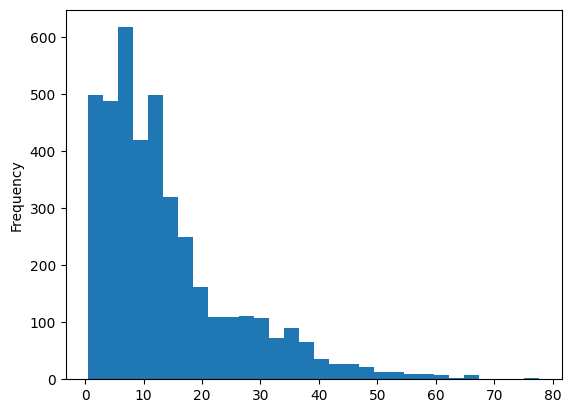

In [16]:
# Check the kWhDelivered when the doneChargingTime is null to avoid station issues
data_charge[data_charge["doneChargingTime"].isnull()]["kWhDelivered"].plot.hist(bins=30)

<Axes: ylabel='Frequency'>

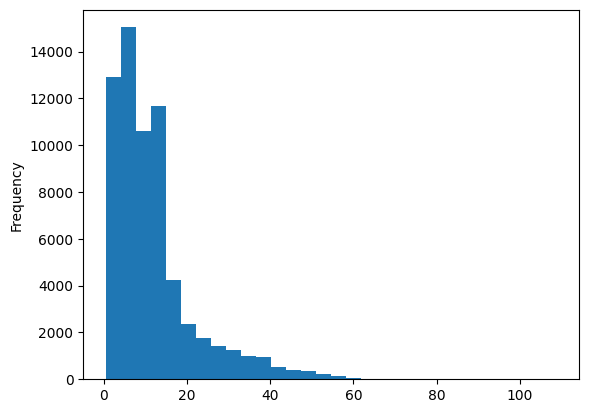

In [17]:
# Check the kWhDelivered
data_charge["kWhDelivered"].plot.hist(bins=30)

In [18]:
data_charge[data_charge["kWhDelivered"] <= 0]

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs,endChargingTime


# Feature Engineering

In [19]:
# Add a column "chargingDurationMin" that covers information how long the cars took to charge (endChargingTime-connectionTime)
data_charge["chargingDurationMin"] = (
    data_charge["endChargingTime"] - data_charge["connectionTime"]
).dt.total_seconds() / 60

In [20]:
# Add a column "blockingDurationMin" that covers information how long the cars stayed on a slot without charging (disconnectTime-endChargingTime)
data_charge["blockingDurationMin"] = (
    data_charge["disconnectTime"] - data_charge["endChargingTime"]
).dt.total_seconds() / 60

In [21]:
# Check if disconnectTime is larger or equal than doneChargingTime and this should be larger or equal than connection time
valid_records = data_charge[
    (data_charge["disconnectTime"] >= data_charge["endChargingTime"])
    & (data_charge["endChargingTime"] >= data_charge["connectionTime"])
]

valid_count = len(valid_records)
total_count = len(data_charge)

print(f"Amount valid records: {valid_count}")
print(f"Amount records: {total_count}")
print(f"Valid records ratio: {valid_count / total_count * 100:.2f}%")

invalid_records = data_charge[
    ~(
        (data_charge["disconnectTime"] >= data_charge["endChargingTime"])
        & (data_charge["endChargingTime"] >= data_charge["connectionTime"])
    )
]

Amount valid records: 60623
Amount records: 65037
Valid records ratio: 93.21%


In [22]:
num_negative_charging_duration = len(data_charge[data_charge["chargingDurationMin"] < 0])
num_negative_blocking_duration = len(data_charge[data_charge["blockingDurationMin"] < 0])
print(
    f"Number of records with negative charging {num_negative_charging_duration} and blocking durations: {num_negative_blocking_duration}"
)

Number of records with negative charging 27 and blocking durations: 4387


In [23]:
data_charge = data_charge[data_charge["chargingDurationMin"] >= 0]

In [24]:
# Filter records where chargingDurationMin is less than 0
negative_blocking_duration = data_charge[data_charge["blockingDurationMin"] < 0]
negative_blocking_duration.describe()

,Unnamed: 0,kWhDelivered,siteID,userID,chargingDurationMin,blockingDurationMin
count,4387.000000,4387.000000,4387.000000,3329.000000,4387.000000,4387.000000
mean,4791.890586,14.239556,1.268977,1458.393812,261.420910,-0.933618
std,3401.268410,12.575748,0.443478,1532.613614,243.599541,1.271500
min,0.000000,0.508000,1.000000,22.000000,4.216667,-59.933333
25%,1850.000000,5.379000,1.000000,410.000000,109.875000,-0.983333
50%,4296.000000,11.161000,1.000000,832.000000,205.850000,-0.966667
75%,7407.500000,19.239500,2.000000,2052.000000,356.950000,-0.950000
max,15135.000000,108.797242,2.000000,17097.000000,9013.966667,-0.016667


In [25]:
data_charge.loc[
    (data_charge["blockingDurationMin"] < 0) & (data_charge["blockingDurationMin"] >= -1),
    "blockingDurationMin",
] = 0

In [26]:
data_charge = data_charge[data_charge["blockingDurationMin"] >= -1]

=> We need a time buffer since we have some messurement problems.
Possible reasons: The done charge sensor only reacts with 30Hz. Therefore some messurements deviations are okay.

TODO: Analyse the deviations

# Outlier analysis

In [27]:
# Get a brief overview
data_charge.describe()

,Unnamed: 0,kWhDelivered,siteID,userID,chargingDurationMin,blockingDurationMin
count,65008.000000,65008.000000,65008.000000,47814.000000,65008.000000,65008.000000
mean,4623.701006,11.738340,1.482710,1821.987284,216.171861,160.350137
std,3537.700656,10.279175,0.499705,2648.096909,189.140625,236.064364
min,0.000000,0.501000,1.000000,1.000000,0.000000,0.000000
25%,1806.000000,5.064000,1.000000,436.000000,95.233333,0.100000
50%,3858.000000,9.104500,1.000000,826.000000,167.458333,75.650000
75%,6760.000000,14.129000,2.000000,1813.000000,291.433333,281.054167
max,15291.000000,108.797242,2.000000,19923.000000,12000.950000,9367.283333


The max kWhDelivered, chargingDurationMin and blockingDurationMin seem to be suspect! Maybe there are outliers in the dataset. Lets check if such high values for kWhDelivered are even technically possible.

After checking the EV-Database (https://ev-database.org/de/cheatsheet/useable-battery-capacity-electric-car) (Accessed 22.11.2024) the mean usable battery capacity is around 72 kWh, while the highest usable battery capacity is 123 kWh. So from a technical and contextual view, values such as 108.79 are possible in kWhDelivered column.

Since our dataset only covers one datapoint which deviates a lot from the other samples, our model would not be able to learn this pattern. In addition we would also not be able to test how our model performs which such high kWhDelivered.

In [28]:
data_charge = data_charge.drop(data_charge[data_charge["kWhDelivered"] > 80].index)

According to Shell, a charging session can last up to 14 hours (https://www.shell.de/geschaeftskunden/shell-card-tankkarten/shell-card-blog/ladezeit-e-auto.html). So lets check how many overreach it and drop them

In [29]:
threshold_minutes = 14 * 60

# Count the records with chargingDurationMin greater than 14 hours
num_over_14_hours = len(data_charge[data_charge["chargingDurationMin"] > threshold_minutes])
print(f"Number of records with charging duration over 14 hours: {num_over_14_hours}")

# Drop the records with chargingDurationMin greater than 14 hours
data_charge = data_charge[data_charge["chargingDurationMin"] <= threshold_minutes]

Number of records with charging duration over 14 hours: 215


TODO: Was mit diesen Datensätzen machen?
3 Sigma Regel anwenden; oder Perzentile analysieren oder googlen wie lange baterien zum laden brauchen und dann Outlier droppen.

In [30]:
data_charge.describe()

,Unnamed: 0,kWhDelivered,siteID,userID,chargingDurationMin,blockingDurationMin
count,64791.000000,64791.000000,64791.000000,47722.000000,64791.000000,64791.000000
mean,4621.675125,11.714893,1.481425,1821.865408,211.666705,159.514389
std,3535.929797,10.247821,0.499659,2648.075596,154.827374,228.901655
min,0.000000,0.501000,1.000000,1.000000,0.000000,0.000000
25%,1806.000000,5.057500,1.000000,436.000000,94.958333,0.100000
50%,3855.000000,9.080000,1.000000,826.000000,166.866667,75.850000
75%,6757.500000,14.111500,2.000000,1813.000000,289.758333,281.058333
max,15291.000000,77.700000,2.000000,19923.000000,838.583333,9367.283333


## Insight: Datapoints with negative charge and blockingDuration. Additionaly there also data with very high charge duration

<Axes: xlabel='connectionTime'>

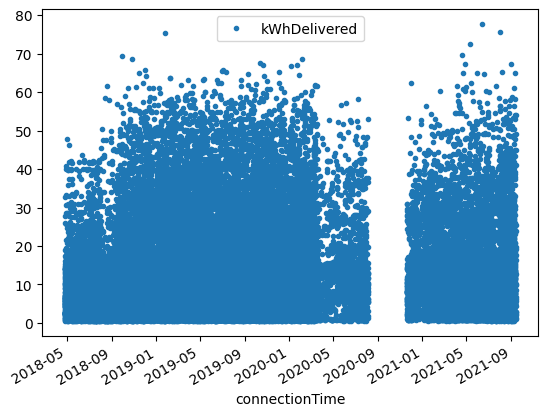

In [31]:
data_charge[["kWhDelivered", "connectionTime"]].set_index("connectionTime").plot(style=".")

Explore now the weather dataset

In [32]:
data_weather.head(3)

,city,timestamp,temperature,cloud_cover,cloud_cover_description,pressure,windspeed,precipitation,felt_temperature
0,Burbank,2018-01-01 08:53:00,9.0,33.0,Fair,991.75,9.0,0.0,8.0
1,Burbank,2018-01-01 09:53:00,9.0,33.0,Fair,992.08,0.0,0.0,9.0
2,Burbank,2018-01-01 10:53:00,9.0,21.0,Haze,992.08,0.0,0.0,9.0


In [33]:
data_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29244 entries, 0 to 29243
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   city                     29244 non-null  object 
 1   timestamp                29244 non-null  object 
 2   temperature              29219 non-null  float64
 3   cloud_cover              29224 non-null  float64
 4   cloud_cover_description  29224 non-null  object 
 5   pressure                 29236 non-null  float64
 6   windspeed                29158 non-null  float64
 7   precipitation            29244 non-null  float64
 8   felt_temperature         29218 non-null  float64
dtypes: float64(6), object(3)
memory usage: 2.0+ MB


In [34]:
data_weather.describe()

,temperature,cloud_cover,pressure,windspeed,precipitation,felt_temperature
count,29219.000000,29224.000000,29236.000000,29158.000000,29244.000000,29218.000000
mean,17.885622,30.107993,986.879400,8.566568,0.059360,17.731433
std,6.454604,5.400388,3.607065,6.699889,0.471682,6.321100
min,2.000000,4.000000,971.000000,0.000000,0.000000,0.000000
25%,13.000000,26.000000,984.500000,6.000000,0.000000,13.000000
50%,17.000000,33.000000,986.480000,7.000000,0.000000,17.000000
75%,22.000000,34.000000,989.110000,13.000000,0.000000,22.000000
max,46.000000,47.000000,999.650000,57.000000,18.540000,42.000000


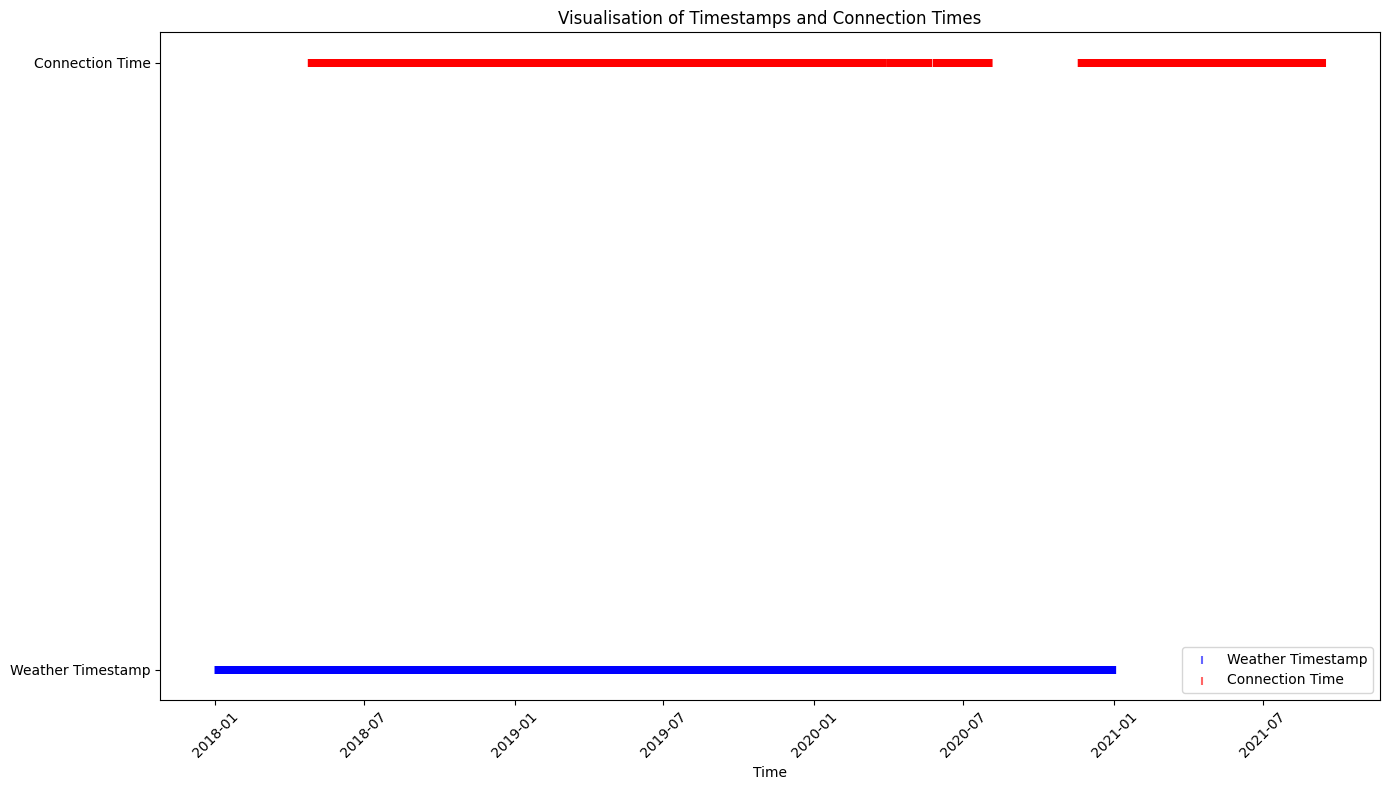

In [39]:

data_weather['timestamp'] = pd.to_datetime(data_weather['timestamp'])
data_charge['connectionTime'] = pd.to_datetime(data_charge['connectionTime'])

data_weather = data_weather.sort_values(by='timestamp')
data_charge = data_charge.sort_values(by='connectionTime')

plt.figure(figsize=(14, 8))

plt.scatter(data_weather['timestamp'], [1]*len(data_weather), marker='|', color='b', alpha=0.6, label='Weather Timestamp')

plt.scatter(data_charge['connectionTime'], [2]*len(data_charge), marker='|', color='r', alpha=0.6, label='Connection Time')

plt.title('Visualisation of Timestamps and Connection Times')
plt.xlabel('Time')
plt.yticks([1, 2], ['Weather Timestamp', 'Connection Time'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()


Note: For specific charging records (their timestamp), there are no weather data records available in the weather dataset. Therefore, we tackle this problem by adding the missing weather data from the external source "visualcrossing" (https://www.visualcrossing.com/weather/weather-data-services). 

In [61]:

additional_weather_data = pd.read_csv('../data/additional_weather_data.csv')
print(additional_weather_data.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6167 entries, 0 to 6166
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              6167 non-null   object 
 1   datetime          6167 non-null   object 
 2   temp              6167 non-null   float64
 3   feelslike         6167 non-null   float64
 4   dew               6167 non-null   float64
 5   humidity          6167 non-null   float64
 6   precip            6167 non-null   float64
 7   precipprob        6167 non-null   int64  
 8   preciptype        77 non-null     object 
 9   snow              6167 non-null   int64  
 10  snowdepth         6167 non-null   float64
 11  windgust          6167 non-null   float64
 12  windspeed         6167 non-null   float64
 13  winddir           6167 non-null   float64
 14  sealevelpressure  6167 non-null   float64
 15  cloudcover        6167 non-null   float64
 16  visibility        6167 non-null   float64


In [62]:
additional_weather_data.head()

,name,datetime,temp,feelslike,dew,humidity,precip,precipprob,preciptype,snow,...,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,severerisk,conditions,icon,stations
0,Burbank,2021-01-01T00:00:00,10.4,10.4,-1.7,43.09,0.0,0,NaN,0,...,1015.0,0.0,16.0,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."
1,Burbank,2021-01-01T01:00:00,15.2,15.2,-5.1,24.18,0.0,0,NaN,0,...,1015.0,0.0,15.5,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."
2,Burbank,2021-01-01T02:00:00,15.1,15.1,-5.1,24.47,0.0,0,NaN,0,...,1015.3,0.0,15.5,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."
3,Burbank,2021-01-01T03:00:00,14.0,14.0,-5.2,26.18,0.0,0,NaN,0,...,1015.3,0.0,15.4,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."
4,Burbank,2021-01-01T04:00:00,14.5,14.5,-6.0,23.72,0.0,0,NaN,0,...,1015.4,0.0,15.5,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."


In [63]:
# Zeige alle Spaltennamen beider Datensätze an
print("Spaltennamen im 'data_weather'-Datensatz:")
print(data_weather.columns.tolist())

print("\nSpaltennamen im 'additional_weather_data'-Datensatz:")
print(additional_weather_data.columns.tolist())

Spaltennamen im 'data_weather'-Datensatz:
['city', 'timestamp', 'temperature', 'cloud_cover', 'cloud_cover_description', 'pressure', 'windspeed', 'precipitation', 'felt_temperature']

Spaltennamen im 'additional_weather_data'-Datensatz:
['name', 'datetime', 'temp', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob', 'preciptype', 'snow', 'snowdepth', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'conditions', 'icon', 'stations']


In [64]:
data_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29244 entries, 0 to 29243
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   city                     29244 non-null  object        
 1   timestamp                29244 non-null  datetime64[ns]
 2   temperature              29219 non-null  float64       
 3   cloud_cover              29224 non-null  float64       
 4   cloud_cover_description  29224 non-null  object        
 5   pressure                 29236 non-null  float64       
 6   windspeed                29158 non-null  float64       
 7   precipitation            29244 non-null  float64       
 8   felt_temperature         29218 non-null  float64       
dtypes: datetime64[ns](1), float64(6), object(2)
memory usage: 2.0+ MB


In [65]:
# Überprüfe Spaltennamen
print("Spaltennamen im 'data_weather'-Datensatz:", data_weather.columns.tolist())
print("Spaltennamen im 'additional_weather_data'-Datensatz:", additional_weather_data.columns.tolist())

# Umbenennen der Spalten in additional_weather_data
additional_weather_data = additional_weather_data.rename(columns={
    'name' : 'city',
    'datetime': 'timestamp',
    'temp': 'temperature',
    'feelslike': 'felt_temperature',
    'cloudcover': 'cloud_cover',
    'sealevelpressure': 'pressure',
    'windspeed': 'windspeed',
    'precip': 'precipitation'
})

# Behalte nur die relevanten Spalten aus additional_weather_data
additional_weather_data = additional_weather_data[['city','timestamp', 'temperature', 'felt_temperature', 
                                                   'cloud_cover', 'pressure', 'windspeed', 'precipitation']]

# Konvertiere den Timestamp in beiden Datensätzen zu datetime
data_weather['timestamp'] = pd.to_datetime(data_weather['timestamp'])
additional_weather_data['timestamp'] = pd.to_datetime(additional_weather_data['timestamp'])

# Ergänze fehlende Einträge durch Zusammenführen der beiden Datensätze
data_weather_combined = pd.concat([data_weather, additional_weather_data], ignore_index=True).drop_duplicates(subset=['timestamp'])

# Sortiere nach Timestamp
data_weather_combined = data_weather_combined.sort_values(by='timestamp').reset_index(drop=True)

# Überprüfe den kombinierten Datensatz
print(data_weather_combined.head())
print(data_weather_combined.tail())

# Speichere den kombinierten Datensatz
data_weather_combined.to_csv('../data/combined_weather_data.csv', index=False)
print("Der kombinierte Datensatz wurde erfolgreich gespeichert.")


Spaltennamen im 'data_weather'-Datensatz: ['city', 'timestamp', 'temperature', 'cloud_cover', 'cloud_cover_description', 'pressure', 'windspeed', 'precipitation', 'felt_temperature']
Spaltennamen im 'additional_weather_data'-Datensatz: ['name', 'datetime', 'temp', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob', 'preciptype', 'snow', 'snowdepth', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'conditions', 'icon', 'stations']
      city           timestamp  temperature  cloud_cover  \
0  Burbank 2018-01-01 08:53:00          9.0         33.0   
1  Burbank 2018-01-01 09:53:00          9.0         33.0   
2  Burbank 2018-01-01 10:53:00          9.0         21.0   
3  Burbank 2018-01-01 11:53:00          9.0         29.0   
4  Burbank 2018-01-01 12:53:00          8.0         33.0   

  cloud_cover_description  pressure  windspeed  precipitation  \
0                    Fair    991.75       

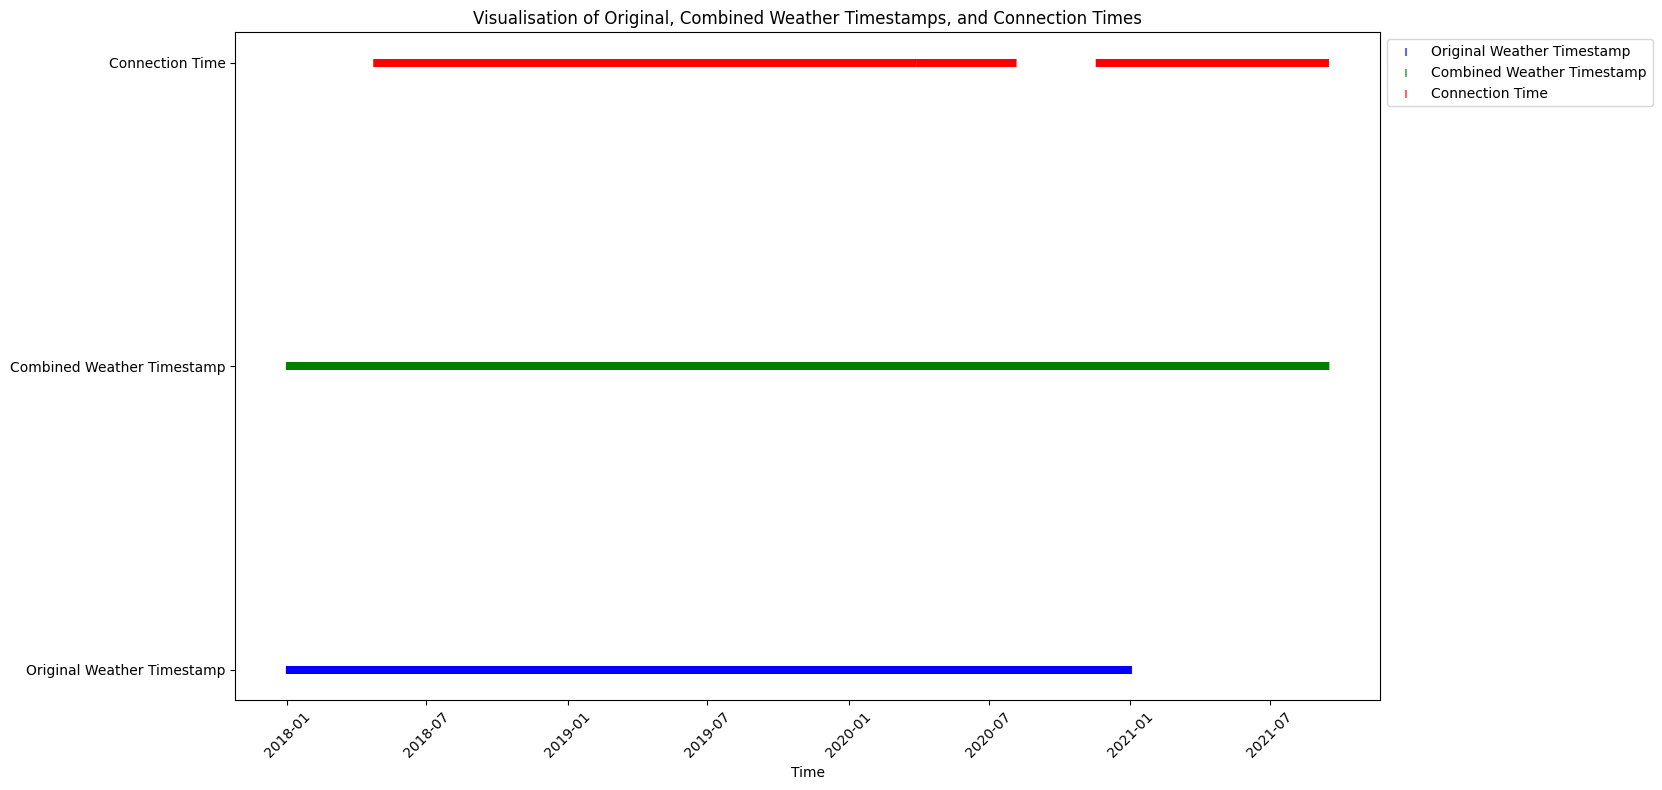

In [67]:

# Timestamp-Umwandlung und Sortierung der Datensätze
data_weather['timestamp'] = pd.to_datetime(data_weather['timestamp'])
data_weather_combined['timestamp'] = pd.to_datetime(data_weather_combined['timestamp'])
data_charge['connectionTime'] = pd.to_datetime(data_charge['connectionTime'])

data_weather = data_weather.sort_values(by='timestamp')
data_weather_combined = data_weather_combined.sort_values(by='timestamp')
data_charge = data_charge.sort_values(by='connectionTime')

# Plot der Timestamps
plt.figure(figsize=(14, 8))

# Originale Wetterdaten (blau)
plt.scatter(data_weather['timestamp'], [1] * len(data_weather), marker='|', color='b', alpha=0.6, label='Original Weather Timestamp')

# Ergänzte Wetterdaten (grün)
plt.scatter(data_weather_combined['timestamp'], [1.5] * len(data_weather_combined), marker='|', color='g', alpha=0.6, label='Combined Weather Timestamp')

# Verbindungstimestamps (rot)
plt.scatter(data_charge['connectionTime'], [2] * len(data_charge), marker='|', color='r', alpha=0.6, label='Connection Time')

# Titel und Achsenbeschriftungen
plt.title('Visualisation of Original, Combined Weather Timestamps, and Connection Times')
plt.xlabel('Time')
plt.yticks([1, 1.5, 2], ['Original Weather Timestamp', 'Combined Weather Timestamp', 'Connection Time'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))  # Legende außerhalb des Plots
plt.show()


In [36]:
data_charge.to_pickle("data_charge_prep.pkl")

# Backup 

In [37]:
# Insights and parsing of user inputs


data_charge["userInputs_parsed"] = data_charge["userInputs"].apply(str)
data_charge["userInputs_parsed"] = data_charge.userInputs.apply(
    lambda x: ast.literal_eval(x) if type(x) == str else []
)
data_charge["userInputs_parsed"].iloc[5]
data_charge["userInputs_parsed_len"] = data_charge["userInputs_parsed"].apply(len)

data_charge["userInputs_parsed_len"].value_counts()
data_charge[data_charge["userInputs_parsed_len"] == 3]["userInputs_parsed"].iloc[0]

[{'WhPerMile': 400,
  'kWhRequested': 8.0,
  'milesRequested': 20,
  'minutesAvailable': 316,
  'modifiedAt': 'Thu, 02 Jan 2020 15:23:27 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Thu, 02 Jan 2020 20:39:27 GMT',
  'userID': 3399},
 {'WhPerMile': 400,
  'kWhRequested': 8.0,
  'milesRequested': 20,
  'minutesAvailable': 177,
  'modifiedAt': 'Thu, 02 Jan 2020 18:04:40 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Thu, 02 Jan 2020 18:20:27 GMT',
  'userID': 3399},
 {'WhPerMile': 400,
  'kWhRequested': 8.0,
  'milesRequested': 20,
  'minutesAvailable': 191,
  'modifiedAt': 'Thu, 02 Jan 2020 18:05:13 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Thu, 02 Jan 2020 18:34:27 GMT',
  'userID': 3399}]